# Online Retail II: Sales and Customer Analysis

**Goal:** Clean a year-spanning retail transactions dataset, explore sales patterns, and segment
customers with RFM analysis.

**Dataset:** Online Retail II (UCI Machine Learning Repository), about 1.07 million transactions
from a UK-based online gift retailer, December 2009 to December 2011.

**Contents**
1. Data Loading
2. Data Cleaning
3. Building Analysis Datasets
4. Exploratory Data Analysis
5. Customer Segmentation (RFM)

In [1]:
import sys

print(sys.executable)

c:\Users\HP\OneDrive\Documents\Online_Retail_Data_Science_Project\.venv\Scripts\python.exe


In [2]:
import openpyxl

print(openpyxl.__version__)

3.1.5


In [3]:
import pandas as pd

file_path = "../data/online_retail_II.xlsx"

excel_file = pd.ExcelFile(file_path)

print(excel_file.sheet_names)

['Year 2009-2010', 'Year 2010-2011']


In [4]:
data_2009_2010 = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print(data_2009_2010.shape)

(525461, 8)


In [5]:
data_2010_2011 = pd.read_excel(
    file_path,
    sheet_name="Year 2010-2011"
)

print(data_2010_2011.shape)

(541910, 8)


In [6]:
data = pd.concat(
    [data_2009_2010, data_2010_2011],
    ignore_index=True
)

print(data.shape)

(1067371, 8)


In [7]:
data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [8]:
data.shape

(1067371, 8)

In [9]:
data.columns

Index(['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'Price', 'Customer ID', 'Country'],
      dtype='str')

In [10]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 65.1+ MB


In [11]:
data.isnull().sum()

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64

In [12]:
(data.isnull().sum() / len(data)) * 100

Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    22.766873
Country         0.000000
dtype: float64

In [13]:
data.duplicated().sum()

np.int64(34335)

In [14]:
(data["Quantity"] < 0).sum() #checking for negative values

np.int64(22950)

In [15]:
negative_data = data[data["Quantity"] < 0]

negative_data.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia


In [16]:
negative_data["Invoice"].head(20)

178    C489449
179    C489449
180    C489449
181    C489449
182    C489449
183    C489449
184    C489449
185    C489449
186    C489449
196    C489459
197    C489459
198    C489459
199    C489459
200    C489459
201    C489459
202    C489459
203    C489459
204    C489459
205    C489459
206    C489459
Name: Invoice, dtype: object

In [17]:
negative_data["Invoice"].astype(str).str.startswith("C").sum()

np.int64(19493)

In [18]:
cancelled_invoices = data[
    data["Invoice"].astype(str).str.startswith("C")
]

print(cancelled_invoices.shape)

(19494, 8)


In [19]:
print(cancelled_invoices["Quantity"].min())
print(cancelled_invoices["Quantity"].max())

-80995
1


In [20]:
data[data["Quantity"] == -80995]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.08,16446.0,United Kingdom


In [21]:
print("Zero prices:", (data["Price"] == 0).sum())
print("Negative prices:", (data["Price"] < 0).sum())

Zero prices: 6202
Negative prices: 5


In [22]:
data[data["Price"] < 0]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [23]:
zero_price_data = data[data["Price"] == 0]

zero_price_data.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom


In [24]:
zero_price_data["Description"].value_counts().head(15)

Description
check                           162
?                                92
damages                          84
damaged                          81
found                            28
missing                          27
sold as set on dotcom            20
Damaged                          17
adjustment                       16
OWL DOORSTOP                     15
POLYESTER FILLER PAD 45x45cm     12
dotcom                           12
amazon                           11
POLYESTER FILLER PAD 40x40cm     10
IVORY KITCHEN SCALES             10
Name: count, dtype: int64

In [25]:
duplicate_data = data[data.duplicated(keep=False)]

duplicate_data.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [26]:
data.loc[
    (data["Invoice"] == "489517") &
    (data["StockCode"] == "21912"),
    :
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country


In [27]:
print(data["Invoice"].dtype)
print(data["Invoice"].head())
print(data["StockCode"].dtype)
print(data["StockCode"].head())

object
0    489434
1    489434
2    489434
3    489434
4    489434
Name: Invoice, dtype: object
object
0     85048
1    79323P
2    79323W
3     22041
4     21232
Name: StockCode, dtype: object


In [28]:
print(repr(data.loc[362, "Invoice"]))
print(repr(data.loc[362, "StockCode"]))

489517
21913


In [29]:
data.loc[
    (data["Invoice"] == 489517) &
    (data["StockCode"] == 21912)
]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom


In [30]:
data.loc[[363, 371, 394]].duplicated()

363    False
371     True
394     True
dtype: bool

In [31]:
print("Total rows:", len(data))
print("Exact duplicate rows:", data.duplicated().sum())
print("Rows after removing exact duplicates:", len(data.drop_duplicates()))

Total rows: 1067371
Exact duplicate rows: 34335
Rows after removing exact duplicates: 1033036


In [32]:
clean_data = data.drop_duplicates().copy()

print("Original shape:", data.shape)
print("Cleaned shape:", clean_data.shape)
print("Remaining duplicates:", clean_data.duplicated().sum())

Original shape: (1067371, 8)
Cleaned shape: (1033036, 8)
Remaining duplicates: 0


Data Cleaning — Duplicate Records

Observation: The original dataset contained 1,067,371 rows and 8 columns. I identified 34,335 exact duplicate rows, approximately 3.22% of the original dataset.

Action: I created a separate DataFrame named clean_data using drop_duplicates() to remove exact duplicate rows while preserving the original dataset.

Result: The cleaned dataset contains 1,033,036 rows and 8 columns, with no remaining exact duplicate rows.

Reason: Exact duplicate records can affect sales calculations and customer-level analysis. 

In [33]:
print("Missing values in each column:")
print(clean_data.isnull().sum())

Missing values in each column:
Invoice             0
StockCode           0
Description      4275
Quantity            0
InvoiceDate         0
Price               0
Customer ID    235151
Country             0
dtype: int64


In [34]:
missing_percent = (clean_data.isnull().sum() / len(clean_data)) * 100

print(missing_percent.round(2))

Invoice         0.00
StockCode       0.00
Description     0.41
Quantity        0.00
InvoiceDate     0.00
Price           0.00
Customer ID    22.76
Country         0.00
dtype: float64


Missing Values Analysis

Observation:
- Description: 4,275 missing values (0.41%).
- Customer ID: 235,151 missing values (22.76%).
- All other columns have no missing values.

Decision:
- Keep rows with missing Customer ID for general sales analysis because they may contain useful transaction information.
- Investigate missing Description values before deciding whether to remove or fill them.
- For customer-level analysis, use records with valid customer IDs when appropriate.

Reason: Removing every row with a missing customer ID would discard a substantial amount of potentially useful data.

In [35]:
missing_description_data = clean_data[
    clean_data["Description"].isnull()
]

missing_description_data.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom


In [36]:
print("Missing Description and zero Price:",
      ((clean_data["Description"].isnull()) &
       (clean_data["Price"] == 0)).sum())

print("Missing Description and missing Customer ID:",
      ((clean_data["Description"].isnull()) &
       (clean_data["Customer ID"].isnull())).sum())

print("Missing Description with positive Quantity:",
      ((clean_data["Description"].isnull()) &
       (clean_data["Quantity"] > 0)).sum())

print("Missing Description with negative Quantity:",
      ((clean_data["Description"].isnull()) &
       (clean_data["Quantity"] < 0)).sum())

Missing Description and zero Price: 4275
Missing Description and missing Customer ID: 4275
Missing Description with positive Quantity: 1642
Missing Description with negative Quantity: 2633


Investigation of Missing Descriptions

Observation: All 4,275 records with missing descriptions also have zero prices and missing customer IDs. Of these, 1,642 have positive quantities and 2,633 have negative quantities.

Decision: Records were retained during investigation (see update below).

Reason: Their exact business meaning is uncertain. Removing them without further investigation could discard potentially useful transaction information. Their treatment will depend on the analysis being performed.



**Update:** All 4,275 rows have price 0 and no Customer ID, so they are removed by the
`Price > 0` filter when the sales table is built. No separate treatment is needed.

In [37]:
# Checking cancelled invoices
cancelled_invoices = clean_data[
    clean_data["Invoice"].astype(str).str.startswith("C")
]

print("Cancelled invoice rows:", len(cancelled_invoices))

print("Cancelled invoice unique numbers:",
      cancelled_invoices["Invoice"].nunique())

print("Cancelled invoice rows with positive quantity:",
      (cancelled_invoices["Quantity"] > 0).sum())

print("Cancelled invoice rows with negative quantity:",
      (cancelled_invoices["Quantity"] < 0).sum())

Cancelled invoice rows: 19104
Cancelled invoice unique numbers: 8292
Cancelled invoice rows with positive quantity: 1
Cancelled invoice rows with negative quantity: 19103


In [38]:
# Find the positive-quantity row in cancelled invoices
unusual_row = cancelled_invoices[
    cancelled_invoices["Quantity"] > 0]
display(unusual_row)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


In [39]:
data[data["Invoice"] == "C496350"]

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
76799,C496350,M,Manual,1,2010-02-01 08:24:00,373.57,NaN,United Kingdom


**Observation:** One cancelled invoice (C496350) has a positive quantity. Its StockCode is `M`
(Manual), so it is an accounting entry, not a product return.

**Decision:** No separate action needed, because Manual entries are excluded later.

In [40]:
data[data["Description"] == "Manual"].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
2697,489609,M,Manual,1,2009-12-01 14:50:00,4.00,NaN,United Kingdom
3053,C489651,M,Manual,-1,2009-12-01 16:48:00,5.10,17804.0,United Kingdom
5897,C489859,M,Manual,-1,2009-12-02 14:45:00,69.57,NaN,United Kingdom
9259,C490126,M,Manual,-1,2009-12-03 18:12:00,5.95,15884.0,United Kingdom
9307,C490129,M,Manual,-1,2009-12-03 18:26:00,1998.49,15482.0,United Kingdom
11310,490300,M,Manual,1,2009-12-04 14:19:00,0.85,12970.0,United Kingdom
11311,490300,M,Manual,1,2009-12-04 14:19:00,0.21,12970.0,United Kingdom
16107,490727,M,Manual,1,2009-12-07 16:38:00,0.00,17231.0,United Kingdom
17273,C490748,M,Manual,-1,2009-12-07 18:14:00,309.73,12748.0,United Kingdom
17386,490760,M,Manual,1,2009-12-08 09:49:00,10.00,14295.0,United Kingdom


In [41]:
# Identify cancellation invoices
clean_data["IsCancelled"] = (
    clean_data["Invoice"]
    .astype(str)
    .str.startswith("C", na=False)
)

# Check the results
print(clean_data["IsCancelled"].value_counts())

IsCancelled
False    1013932
True       19104
Name: count, dtype: int64


In [42]:
# Count zero and negative prices
print("Rows with zero price:",
      (clean_data["Price"] == 0).sum())

print("Rows with negative price:",
      (clean_data["Price"] < 0).sum())

print("Rows with positive price:",
      (clean_data["Price"] > 0).sum())

Rows with zero price: 6014
Rows with negative price: 5
Rows with positive price: 1027017


In [43]:
# Display all rows with negative prices
negative_price_rows=clean_data[clean_data["Price"]<0]
negative_price_rows

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False


In [44]:
# Identify bad-debt adjustment records
clean_data["IsBadDebtAdjustment"] = (
    clean_data["Description"]
    .fillna("")
    .str.strip()
    .str.lower()
    .eq("adjust bad debt")
)

print("Bad-debt adjustment rows:",
      clean_data["IsBadDebtAdjustment"].sum())

Bad-debt adjustment rows: 6


In [45]:
# Display every bad-debt adjustment
bad_debt_rows = clean_data[
    clean_data["IsBadDebtAdjustment"]
]

display(bad_debt_rows)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,IsBadDebtAdjustment
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,False,True
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,False,True
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,False,True
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,False,True
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,False,True
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,False,True


## Data Cleaning: Manual, Zero-Price, Negative-Quantity, and Bad-Debt Rows

**Manual entries (`StockCode == "M"`):** 1,392 rows with prices up to £38,970. 38% are cancelled
and net revenue is negative. Large entries appear as invoice/cancellation pairs of equal amounts.
**Decision:** Exclude. These are accounting corrections, not product sales.

**Zero-price rows:** 6,014 rows, 98.8% with no Customer ID, with descriptions such as "damages",
"check", "missing", and "found". **Decision:** Exclude. They are stock-count adjustments, not purchases.

**Negative quantities that are not cancellations:** 3,393 rows, all with price 0 and no Customer ID
(damaged, smashed, thrown away). They are a subset of the zero-price rows.
**Decision:** Exclude. The filter `Price > 0` handles both groups.

**Bad-debt rows (StockCode B):** 6 rows with large positive and negative prices (up to £53,594),
no Customer ID, flagged with `IsBadDebtAdjustment`.
**Decision:** Exclude as accounting adjustments. They are also included in the `IsNonProduct`
flag created later in this notebook.

## Data Cleaning: Non-Product Stock Codes

**Question:** Does every row in `StockCode` represent a real product a customer bought?

**Why it matters:** Postage, fees, discounts, and manual entries are accounting lines, not products.
If left in, they distort product rankings and revenue analysis.

**Approach:** Standardize the codes, find codes that don't follow the normal product format,
then manually review each one using its description.

In [46]:
# StockCode mixes numbers and text in the Excel file, so convert to clean uppercase strings
clean_data["Invoice"] = clean_data["Invoice"].astype(str)
clean_data["StockCode"] = clean_data["StockCode"].astype(str).str.strip().str.upper()

print(clean_data["StockCode"].dtype)
clean_data["StockCode"].head()

str


0     85048
1    79323P
2    79323W
3     22041
4     21232
Name: StockCode, dtype: str

**Observation:** `StockCode` was stored with mixed types (integers and strings), which caused
filter mismatches earlier (e.g. `== 489517` vs `== "489517"`).

**Action:** Converted `Invoice` and `StockCode` to strings and standardized `StockCode` to
stripped uppercase.

In [47]:
# Normal product codes: exactly 5 digits, optionally followed by 1-2 letters (e.g. 85123A)
normal_pattern = r"^\d{5}[A-Z]{0,2}$"

is_normal = clean_data["StockCode"].str.match(normal_pattern)

print("Rows with normal codes:    ", is_normal.sum())
print("Rows with non-standard codes:", (~is_normal).sum())

Rows with normal codes:     1027056
Rows with non-standard codes: 5980


In [48]:
odd_codes = clean_data[~is_normal]

odd_summary = (
    odd_codes
    .groupby("StockCode")
    .agg(rows=("Invoice", "size"),
         example_description=("Description", "first"))
    .sort_values("rows", ascending=False)
)

print("Number of distinct non-standard codes:", len(odd_summary))
odd_summary.head(40)

Number of distinct non-standard codes: 61


,rows,example_description
StockCode,,
POST,2086,POSTAGE
DOT,1425,DOTCOM POSTAGE
M,1392,Manual
C2,277,CARRIAGE
D,173,Discount
S,101,SAMPLES
BANK CHARGES,100,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,36,AMAZON FEE


In [49]:
odd_summary.tail(40)

,rows,example_description
StockCode,,
GIFT_0001_40,7,Dotcomgiftshop Gift Voucher £40.00
DCGS0069,6,OOH LA LA DOGS COLLAR
B,6,Adjust bad debt
DCGS0004,5,HAYNES CAMPER SHOULDER BAG
DCGS0072,4,CAT CAMOUFLAGUE COLLAR
DCGS0066N,4,NAVY CUDDLES DOG HOODIE
GIFT_0001_80,4,Dotcomgiftshop Gift Voucher £80.00
ADJUST2,3,Adjustment by Peter on Jun 25 2010
SP1002,3,KID'S CHALKBOARD/EASEL


**Observation:** 5,980 rows (61 distinct codes) did not follow the normal product format of
5 digits plus optional letters. Reviewing each code's description showed a mix of non-products
and real products with unusual codes.

| Type | Codes | Decision |
|---|---|---|
| Shipping / postage | POST, DOT, C2 | Exclude |
| Fees / accounting | BANK CHARGES, AMAZONFEE, CRUK, ADJUST, ADJUST2, B, M, D | Exclude |
| Test entries | TEST001, TEST002 | Exclude |
| Gift vouchers | GIFT_0001_* and GIFT | Exclude (not physical products) |
| Unlabelled zero-price entries | C3 | Exclude |
| Samples (S) | S | Exclude: 97% are cancellation invoices with no Customer ID (write-offs) |
| Placeholder-price item | PADS | Exclude: priced at £0.001, a placeholder rather than a real sale |
| Real products with unusual codes | DCGS* (dog collars, ashtrays, party bags), SP1002 | **Keep** |

**Reason for not deleting by pattern alone:** a regex finds candidates, but deleting every row that
fails the pattern would also remove real products such as DCGS0058. Each code was reviewed by
reading its description.

In [50]:
non_product_codes = ["POST", "DOT", "M", "C2", "D", "S", "BANK CHARGES",
                     "ADJUST", "ADJUST2", "AMAZONFEE", "CRUK", "B",
                     "TEST001", "TEST002", "PADS", "C3", "GIFT"]

# Verify each code actually exists in this dataset
for code in non_product_codes:
    print(f"{code:15} {(clean_data['StockCode'] == code).sum():>6} rows")

POST              2086 rows
DOT               1425 rows
M                 1392 rows
C2                 277 rows
D                  173 rows
S                  101 rows
BANK CHARGES       100 rows
ADJUST              67 rows
ADJUST2              3 rows
AMAZONFEE           36 rows
CRUK                16 rows
B                    6 rows
TEST001             15 rows
TEST002              2 rows
PADS                19 rows
C3                   1 rows
GIFT                 1 rows


In [51]:
clean_data["IsNonProduct"] = (
    clean_data["StockCode"].isin(non_product_codes)
    | clean_data["StockCode"].str.startswith("GIFT_")
)

print("Non-product rows flagged:", clean_data["IsNonProduct"].sum())
print("Share of dataset: {:.2f}%".format(clean_data["IsNonProduct"].mean() * 100))

Non-product rows flagged: 5820
Share of dataset: 0.56%


**Action:** Created a boolean flag `IsNonProduct` instead of deleting rows.

**Reason:** Flagging keeps the original data intact and lets each later analysis choose what to
include. For example, postage is irrelevant to product rankings but may matter for total
revenue analysis.

## Building Analysis Datasets

**Goal:** Split the cleaned data into purpose-built tables so each analysis uses only the
rows that make sense for it.

| Table | Contains | Used for |
|---|---|---|
| `sales` | Real purchases only | Revenue, product and country analysis |
| `returns` | Cancellations of real products | Return-rate analysis |
| `sales_customers` | Sales with a known Customer ID | RFM segmentation, customer analysis |

In [52]:
clean_data["Revenue"] = clean_data["Quantity"] * clean_data["Price"]
clean_data[["Quantity", "Price", "Revenue"]].head()

,Quantity,Price,Revenue
0,12,6.95,83.4
1,12,6.75,81.0
2,12,6.75,81.0
3,48,2.10,100.8
4,24,1.25,30.0


the sales table

In [53]:
sales = clean_data[
    (~clean_data["IsCancelled"])        # not a cancellation
    & (clean_data["Quantity"] > 0)      # something was actually sold
    & (clean_data["Price"] > 0)         # it had a real price
    & (~clean_data["IsNonProduct"])     # and it's a real product
].copy()

print("Sales rows:", len(sales))

Sales rows: 1003340


the returns table

In [54]:
returns = clean_data[
    (clean_data["IsCancelled"])
    & (clean_data["Quantity"] < 0)
    & (~clean_data["IsNonProduct"])
].copy()

print("Return rows:", len(returns))

Return rows: 17914


the customer table

In [55]:
sales_customers = sales.dropna(subset=["Customer ID"]).copy()
sales_customers["Customer ID"] = sales_customers["Customer ID"].astype(int)

print("Sales rows with a Customer ID:", len(sales_customers))
print("Unique customers:", sales_customers["Customer ID"].nunique())
print("Share of sales rows with a Customer ID: {:.1f}%".format(
    len(sales_customers) / len(sales) * 100))

Sales rows with a Customer ID: 776579
Unique customers: 5852
Share of sales rows with a Customer ID: 77.4%


**Observation:** About 22.6% of sales rows have no Customer ID.

**Decision:** Keep these rows in `sales` (they are real revenue) but exclude them from
`sales_customers`, since customer-level analysis such as RFM needs a known customer.

**Consequence to remember:** customer-based revenue will be lower than total revenue. This is a
limitation of the data, and I will mention it in my project conclusions.

In [56]:
sales["InvoiceDate"] = pd.to_datetime(sales["InvoiceDate"])
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.month
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

sales[["InvoiceDate", "Year", "Month", "YearMonth", "DayOfWeek", "Hour"]].head()

,InvoiceDate,Year,Month,YearMonth,DayOfWeek,Hour
0,2009-12-01 07:45:00,2009,12,2009-12,Tuesday,7
1,2009-12-01 07:45:00,2009,12,2009-12,Tuesday,7
2,2009-12-01 07:45:00,2009,12,2009-12,Tuesday,7
3,2009-12-01 07:45:00,2009,12,2009-12,Tuesday,7
4,2009-12-01 07:45:00,2009,12,2009-12,Tuesday,7


In [57]:
sales_customers = sales[sales["Customer ID"].notna()].copy()
sales_customers["Customer ID"] = sales_customers["Customer ID"].astype(int)

important calculations done

In [58]:
total = len(clean_data)

step1 = clean_data[~clean_data["IsCancelled"]]
step2 = step1[~step1["IsNonProduct"]]
step3 = step2[(step2["Quantity"] > 0) & (step2["Price"] > 0)]

print(f"Starting rows (after duplicates):     {total:>10,}")
print(f"Removed: cancellations:               {total - len(step1):>10,}")
print(f"Removed: non-product codes:           {len(step1) - len(step2):>10,}")
print(f"Removed: zero price / bad quantity:   {len(step2) - len(step3):>10,}")
print(f"Final sales rows:                     {len(step3):>10,}")
print("Matches sales table:", len(step3) == len(sales))

Starting rows (after duplicates):      1,033,036
Removed: cancellations:                   19,104
Removed: non-product codes:                4,630
Removed: zero price / bad quantity:        5,962
Final sales rows:                      1,003,340
Matches sales table: True


In [59]:
print("Total sales revenue:   £{:,.2f}".format(sales["Revenue"].sum()))
print("Total returns value:   £{:,.2f}".format(returns["Revenue"].sum()))
print("Unique invoices:", sales["Invoice"].nunique())

Total sales revenue:   £19,643,861.62
Total returns value:   £-716,425.97
Unique invoices: 39516


**Reconciliation:** 1,033,036 cleaned rows became 1,003,340 sales rows. Every removal is
accounted for: 19,104 cancellations, 4,630 non-product rows, and 5,962 zero-price / invalid rows.
Total sales revenue is about £19.64M across 39,516 invoices.

In [60]:
import os

os.makedirs("../data/processed", exist_ok=True)   # creates data/processed if it doesn't exist

sales.to_csv("../data/processed/sales_clean.csv", index=False)
sales_customers.to_csv("../data/processed/sales_customers.csv", index=False)
returns.to_csv("../data/processed/returns.csv", index=False)

print("Saved! Files in data/processed:", os.listdir("../data/processed"))

Saved! Files in data/processed: ['returns.csv', 'sales_clean.csv', 'sales_customers.csv']


# Exploratory Data Analysis (EDA)

**Business questions:**
1. How big is the business? (revenue, orders, customers, average order value)
2. How does revenue change over time? Is there seasonality?
3. Which products and countries drive revenue?
4. When do customers buy? (weekday and hour)

In [61]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## Outlier Check: Order Quantities

**Question:** Are there quantities so extreme that they could distort revenue and product rankings?

In [62]:
print(sales["Quantity"].describe())

sales.nlargest(5, "Quantity")[["Invoice", "StockCode", "Description",
                               "Quantity", "Price", "Customer ID", "InvoiceDate"]]

count    1.003340e+06
mean     1.115080e+01
std      1.287390e+02
min      1.000000e+00
25%      1.000000e+00
50%      4.000000e+00
75%      1.200000e+01
max      8.099500e+04
Name: Quantity, dtype: float64


,Invoice,StockCode,Description,Quantity,Price,Customer ID,InvoiceDate
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.10,13902.0,2010-02-15 11:57:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.10,13902.0,2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.10,13902.0,2010-03-17 13:09:00


In [63]:
big_orders = sales[sales["Quantity"] > 50000]["Invoice"].tolist()
print("Giant sale invoices:", big_orders)

returns[returns["Quantity"] < -50000][["Invoice", "StockCode", "Quantity",
                                       "Price", "Customer ID", "InvoiceDate"]]

Giant sale invoices: ['541431', '581483']


,Invoice,StockCode,Quantity,Price,Customer ID,InvoiceDate
587085,C541433,23166,-74215,1.04,12346.0,2011-01-18 10:17:00
1065883,C581484,23843,-80995,2.08,16446.0,2011-12-09 09:27:00


In [64]:
mistaken_sales = ["581483", "541431"]
mistaken_cancels = ["C581484", "C541433"]

print("Before:", len(sales), len(returns), len(sales_customers))

sales = sales[~sales["Invoice"].isin(mistaken_sales)].copy()
returns = returns[~returns["Invoice"].isin(mistaken_cancels)].copy()
sales_customers = sales_customers[~sales_customers["Invoice"].isin(mistaken_sales)].copy()

print("After: ", len(sales), len(returns), len(sales_customers))

Before: 1003340 17914 776579
After:  1003338 17912 776577


**Observation:** Two orders (invoices 581483 and 541431) had quantities of 80,995 and 74,215 units, far
above the typical row (median quantity 4). Each was cancelled by the same customer within 16 minutes
for exactly the same quantity.

**Decision:** Removed the original sales and their cancellations. They were data-entry errors that
would distort revenue, product rankings, and customer values (the larger one alone was worth £168,470,
about 0.9% of total revenue).

## Outlier Check: Prices and Revenue

**Question:** The quantity check caught two mistaken orders. Could there be errors that quantity alone
would not reveal, such as an unusually high price?

In [65]:
sales.nlargest(5, "Revenue")[["Invoice", "StockCode", "Description",
                              "Quantity", "Price", "Revenue", "Customer ID"]]

,Invoice,StockCode,Description,Quantity,Price,Revenue,Customer ID
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838.0
228042,511465,15044A,PINK PAPER PARASOL,3500,2.55,8925.00,18008.0
873786,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0
578172,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40,15749.0


In [66]:
sales[sales["Price"] > 500][["Invoice", "StockCode", "Description",
                             "Quantity", "Price", "Customer ID"]]

,Invoice,StockCode,Description,Quantity,Price,Customer ID
136403,502451,84016,FLAG OF ST GEORGE CAR FLAG,1,867.79,NaN
192196,507637,84016,FLAG OF ST GEORGE CAR FLAG,1,1157.15,NaN
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,15098.0
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.50,15098.0


In [67]:
sales[sales["StockCode"] == "22502"]["Price"].describe()

count    931.000000
mean       8.060516
std       29.850508
min        2.000000
25%        4.950000
50%        5.950000
75%        8.470000
max      649.500000
Name: Price, dtype: float64

In [68]:
clean_data[(clean_data["Customer ID"] == 15098) & (clean_data["StockCode"] == "22502")][
    ["Invoice", "Description", "Quantity", "Price", "InvoiceDate"]]

,Invoice,Description,Quantity,Price,InvoiceDate
748131,556442,PICNIC BASKET WICKER SMALL,60,4.95,2011-06-10 15:22:00
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,2011-06-10 15:28:00
748143,556446,PICNIC BASKET WICKER 60 PIECES,1,649.50,2011-06-10 15:33:00
748153,C556448,PICNIC BASKET WICKER SMALL,-60,4.95,2011-06-10 15:39:00


In [69]:
clean_data[clean_data["Invoice"].isin(["556444", "C556445", "556446"])][
    ["Invoice", "StockCode", "Description", "Quantity", "Price", "InvoiceDate"]]

,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,2011-06-10 15:28:00
748142,C556445,M,Manual,-1,38970.0,2011-06-10 15:31:00
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,2011-06-10 15:33:00


**Observation:** Invoice 556444 contains 60 "PICNIC BASKET WICKER 60 PIECES" at £649.50 each (£38,970),
while the typical price of this product is about £6, and the same customer bought the small basket
minutes earlier at £4.95. The sale was reversed three minutes later by a Manual entry (C556445) for the
exact same amount. That reversal was removed during cleaning because Manual entries are accounting
lines, so the original sale remained in the sales table. Invoice 556446 repeats the same price
(1 unit, £649.50).

**Decision:** Remove invoices 556444 and 556446 from `sales` and `sales_customers`. This is a likely
data-entry error with strong supporting evidence for 556444; including 556446 is a judgment call
(same customer, product, price, and time window; £649.50 in value).

**Lesson:** Checking only quantity missed this, so outlier checks should cover quantity, price, and
revenue.

In [70]:
price_error_invoices = ["556444", "556446"]

print("Before:", len(sales), len(returns), len(sales_customers))

sales = sales[~sales["Invoice"].isin(price_error_invoices)].copy()
sales_customers = sales_customers[~sales_customers["Invoice"].isin(price_error_invoices)].copy()

print("After: ", len(sales), len(returns), len(sales_customers))

Before: 1003338 17912 776577
After:  1003336 17912 776575


June 2011 revenue: 697939


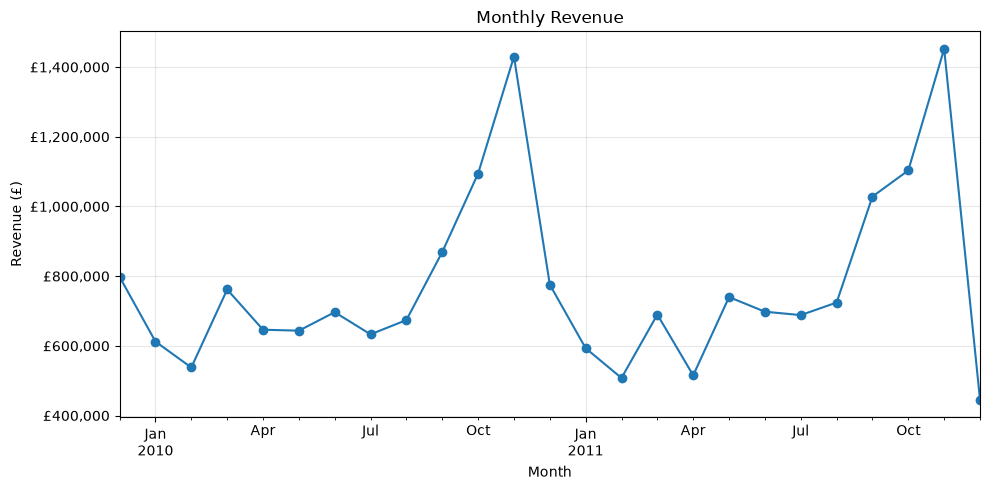

In [71]:

monthly = sales.groupby("YearMonth")["Revenue"].sum()
print("June 2011 revenue:", round(monthly.loc[pd.Period("2011-06", freq="M")]))
monthly.index=monthly.index.to_timestamp()

ax=monthly.plot(marker="o")
ax.set_title("Monthly Revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("£{x:,.0f}"))
plt.tight_layout()
plt.show()

In [72]:
monthly.round(0)

YearMonth
2009-12-01     797901.0
2010-01-01     612297.0
2010-02-01     537910.0
2010-03-01     761706.0
2010-04-01     646341.0
2010-05-01     643492.0
2010-06-01     696583.0
2010-07-01     632994.0
2010-08-01     674038.0
2010-09-01     869243.0
2010-10-01    1094436.0
2010-11-01    1429701.0
2010-12-01     775638.0
2011-01-01     593197.0
2011-02-01     507800.0
2011-03-01     689834.0
2011-04-01     515378.0
2011-05-01     739953.0
2011-06-01     697939.0
2011-07-01     688219.0
2011-08-01     724216.0
2011-09-01    1028320.0
2011-10-01    1103314.0
2011-11-01    1452116.0
2011-12-01     446021.0
Freq: MS, Name: Revenue, dtype: float64

**Observations:**
- Revenue stays between about £500k and £800k for most of the year, then rises from September and
  peaks in November (£1,429,701 in 2010 and £1,452,116 in 2011). A likely reason is the build-up
  to Christmas, as customers, many of them wholesalers, stock up in advance.
- The drop in December 2011 (£446,021) is not a real decline, because the data ends on 9 December,
  so only about nine days of that month are included.
- The weakest month in both years is February (£537,910 in 2010 and £507,800 in 2011).